## Simulation for testing the bayesian analysis

We need a simple way of testing this framework for the bayesian analysis. Following the Bartoss+2025 paper, we want to be able to make background and signal distributions for a given number of transients. 

### The bayesian framework

The framework depends on these source parameters: 
1. Position (RA and DEC)
2. Redshift
3. Peak time of the lightcurve $T_\text{peak}$
4. Source type $k$

### General parameters
We can start with real alerts, until we have a MOC generator. 


### Code
We aleady developed some functions for this in the TransientSimulation, so we will try to use functions from there. 

In [1]:
import numpy as np
import mhealpy as mhp
import healpy as hp
import astropy.units as u
from astropy.time import Time

from Neutrino import Neutrino
from Transient import Transient
from Signal import spatial_signal_pdf#, temporal_signal_pdf, emission_signal_pdf

import sys
sys.path.insert(1, '/Users/cristozilleruelo/Documents/DESY/Thesis/TransientSimulation/')

from random_population import generate_random_transients
from plotting_functions import plot_population, plot_population_with_alerts

sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/')
from ic_visualization import plot_full_map
from ic_processing import read_map




/Users/cristozilleruelo/.local/share/mamba/envs/AMPEL/lib/python3.14/site-packages/ligo/skymap/io/events/ligolw.py:26: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


### Simple Case #1

To simplify the analysis, we can first only take the position as a varying parameter, so we simulate 
* $N_\text{sources} = 10^5$
* $N_{neutrinos} = 100$

Assuming the fixed parameters: 
* Only one type of transient: SN Ib/c
* $d_j = 10\;[\text{Mpc}]$
* $t_\text{peak} \in t_\nu \pm \Delta t_k/2$

#### Background distirbutions
To simulate the background distirbutions, we can distribute 100 alerts randomly in the sky, and test how often you get a neutrino


### Signal distirbutions
We can choose randomly a simulated source as the neutrino progenitor. Then, we can sample a position from the neutrino distribution to locate the source within the alert. Then, we simulate the rest fo the transients randomply and we compute the rubicube distirbution for all sources. 

We can then repeat this process 100 times to see how this distribution behaves. 

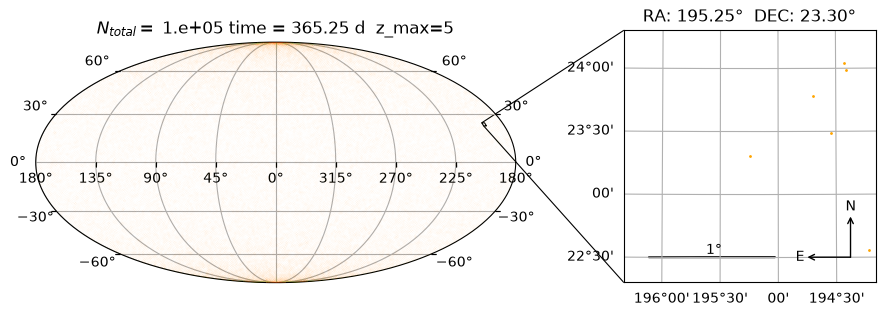

In [2]:
transients = generate_random_transients('SN Ib/c', N_tot=1e5)
plot_population(transients)

Now we get one IC alert

In [3]:
import json
with open('/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/notebooks/ZTF_simulated_alerts.txt', 'r') as file:
    alerts = json.load(file)

In [4]:
alert = alerts[0]
skymap = read_map(alert['healpix_url'], add_units=True)
# import astropy.units as u
# skymap['skymap']['PROBDENSITY'] = skymap['skymap']['PROBDENSITY'] * u.sr ** -1
skymap

{'skymap': <QTable length=62475>
    UNIQ      PROBDENSITY    
                 1 / sr      
   int64        float64      
 --------- ------------------
         4                0.0
         5                0.0
         7                0.0
         8                0.0
         9                0.0
        10                0.0
        11                0.0
        12                0.0
        13                0.0
       ...                ...
 104540811 16.930538997549434
 104540832 17.589181371440958
 104540833 16.580780245523243
 104540834  17.21925779418606
 104540835 16.230977720400862
 104540840  16.84956932339732
 104540841  15.88144177972749
 104540842 16.480437822656445
 104540843 15.532475840597087,
 'header': XTENSION= 'BINTABLE'           / binary table extension                         
 BITPIX  =                    8 / array data type                                
 NAXIS   =                    2 / number of array dimensions                     
 NAXIS1  =          

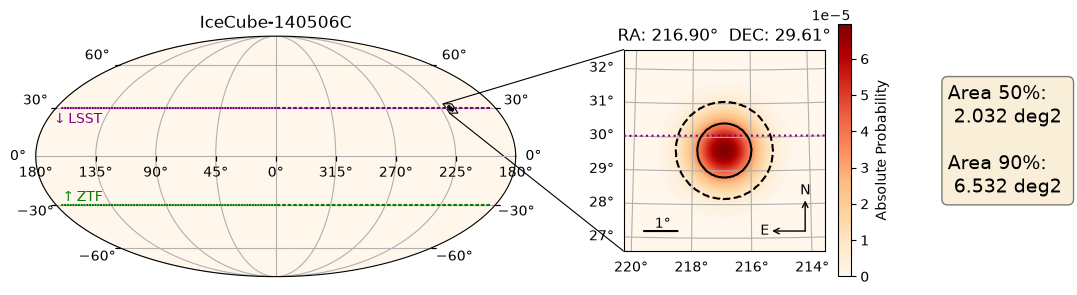

('/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/plots/IceCube-140506C.png',
 <Quantity 6.53239292 deg2>,
 <mhealpy.containers.healpix_map.HealpixMap at 0x123f330e0>)

In [5]:
plot_full_map(skymap)


### Sampler from a Map
Let's try to sample from UNIQ assuming their wwights to be PRODBENSITY

/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/ic_visualization.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(framealpha=1)


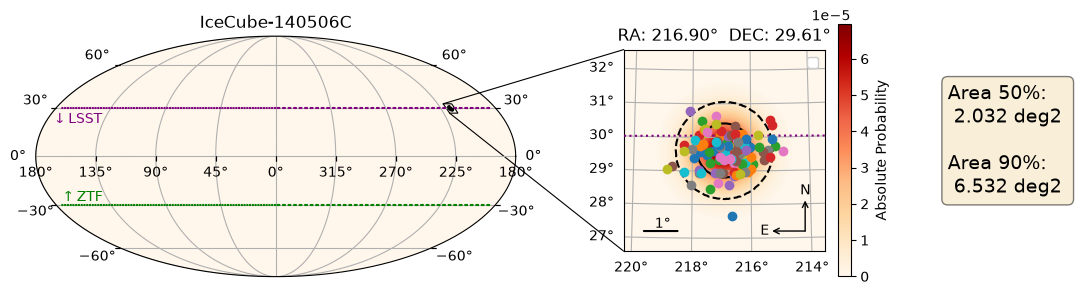

('/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/RubiCube/plots/IceCube-140506C.png',
 <Quantity 6.53239292 deg2>,
 <mhealpy.containers.healpix_map.HealpixMap at 0x125481a70>)

In [6]:
def sample_from_skymap(skymap, sample_size):
    # z_grid = np.linspace(p_cosmology['z_min'], z_max, 1000)
    uniq_grid = skymap['skymap']['UNIQ'].value
    # rates_k = R_z(z_grid, R0.to(u.Mpc ** -3 * u.yr ** -1))
    prob_density = skymap['skymap']['PROBDENSITY'].value

    p_k = prob_density / np.sum(prob_density)
    uniq_sample = np.random.choice(uniq_grid, p=p_k, size=sample_size)

    nside, ipix = mhp.uniq2nest(uniq_sample)
    ra, dec = hp.pix2ang(nside, ipix, nest=True, lonlat=True)
    sources = []
    for ra_i, dec_i in zip(ra, dec):
        sources.append({
            'name': '',
            'ra': ra_i,
            'dec': dec_i,
        })
    return sources
sources = sample_from_skymap(skymap, 100)
plot_full_map(skymap, plot_source=sources)

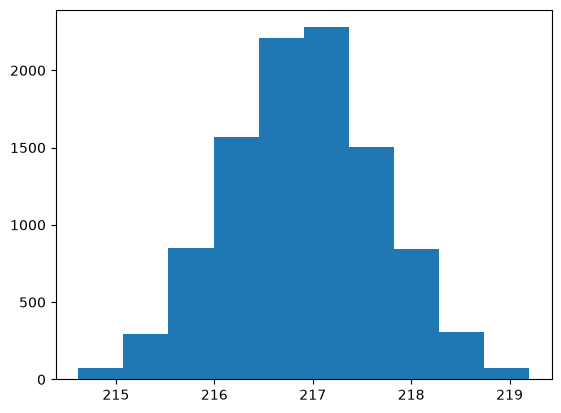

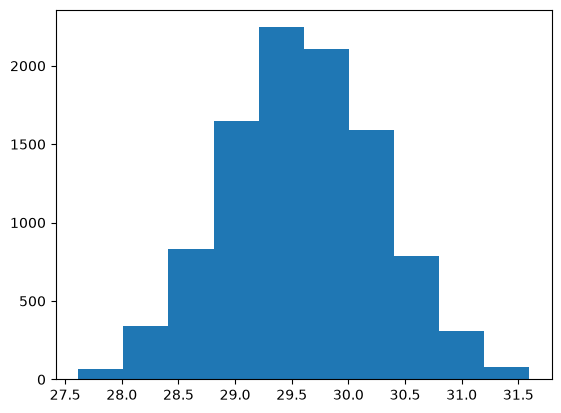

In [7]:
sources = sample_from_skymap(skymap, 10000)
ra = [source['ra'] for source in sources]
dec = [source['dec'] for source in sources]

import matplotlib.pyplot as plt
plt.hist(ra)
plt.show()
plt.hist(dec)
plt.show()

The sampler seems to work correctly. 

## Background distributions
We  start by initating our neutrino, then out transients, and computing the spatial probabilities

In [9]:
nu = Neutrino(skymap, E_i=1e5*u.GeV)
nu.dec_box

[<Quantity 19.61309813 deg>, <Quantity 39.61309813 deg>]

In [10]:
transients
transient_obj = []
for t_i in range(len(transients['z'])):
    transient_params = {
        'ra': transients['ra'][t_i],
        'dec': transients['dec'][t_i],
        'z': transients['z'][t_i],
        't_peak': nu.t + 1 * u.d,
        'name': t_i,
        'p_k': {
            'SN Ib/c': 1.0
        },
        
    }
    transient_obj.append(Transient(transient_params=transient_params))

In [11]:
spatial_dist = []
for t in transient_obj:
    spatial = spatial_signal_pdf(nu, t)
    spatial_dist.append(spatial)
spatial_dist = np.array(spatial_dist)

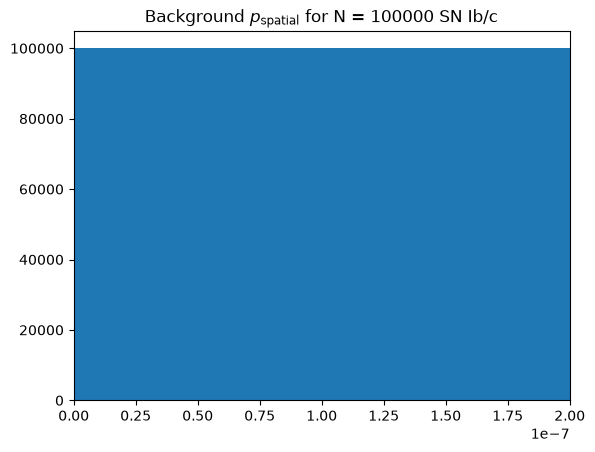

In [12]:
bins = np.logspace(-7, -6, 100)
plt.hist(spatial_dist, bins=100)
plt.title(r'Background $p_\text{spatial}$ for ' + f'N = {len(spatial_dist)} SN Ib/c')
plt.xlim(0, 0.2e-6)
plt.show()

In [13]:
# plot_population(transients, )
skymap

{'skymap': <QTable length=62475>
    UNIQ      PROBDENSITY    
                 1 / sr      
   int64        float64      
 --------- ------------------
 104478713 1112.9824450039046
 104478707 1112.9534264764204
 104478710  1112.824731122761
 104478716 1112.7980410466812
 104478712  1112.684622293444
 104478706  1112.600024681375
 104478715 1112.5293315764484
 104478705  1112.442331452236
 104478708 1112.3692677388076
       ...                ...
        14                0.0
        11                0.0
        12                0.0
        13                0.0
         9                0.0
         5                0.0
         7                0.0
         8                0.0
         4                0.0,
 'header': XTENSION= 'BINTABLE'           / binary table extension                         
 BITPIX  =                    8 / array data type                                
 NAXIS   =                    2 / number of array dimensions                     
 NAXIS1  =          

In [13]:
from time import time
a = time()
spatial_signal_pdf(nu, transient_obj[0])
b = time()
t = (b-a) * u.s
print(t)
print((t * 1e5).to(u.min))

0.00031280517578125 s
0.5213419596354166 min


In [14]:
help(time)

Help on built-in function time in module time:

time()
    time() -> floating-point number

    Return the current time in seconds since the Epoch.
    Fractions of a second may be present if the system clock provides them.



In [15]:
t = transient_obj[0]
if t.ra < 300 * u.deg or t.ra > 320 * u.deg or t.dec < -10 * u.deg or t.dec > 10 * u.deg:
    print('no')
# print(t.ra, t.dec)

no
